# Exercise 4: Rock Crack Detection with a Convolutional Neural Network

- **Course:** PPGEEC2327, Special Topics in Intelligent Information Processing (AI applied to Geophysics), UFRN
- **Reference:** Schuster, G. (2024), *Machine Learning Methods in Geoscience*, SEG, Chapters 8 and 9
- **Task:** reproduce the rock-crack classification lab with a convolutional neural network (CNN) and interpret
  the results. The assignment text mentions AlexNet, but the official lab code (`test_example_CNN.m`) implements
  a small, from-scratch CNN with two convolutional layers, not AlexNet; this notebook follows the official code,
  which is what is actually distributed with the lab.
- **Materials:** the official lab page returns a TLS certificate error over HTTPS but is reachable over plain
  HTTP. The full `CNN_lab.zip` archive, including the real input image and the real labeled training points,
  was downloaded from there and is mirrored at `materials/CNN_crack_lab/CNN_lab`. All results below use that
  real data; no synthetic image is used.

## 1. Loading the official data

`image_input.mat` holds a 457 x 977 grayscale outcrop photo, already rescaled to [-1, 1]. `train_new.mat` holds
400 hand-picked training points: `trainx`/`trainz` are pixel coordinates, and `label` is a 2 x 400 one-hot
matrix (row 0 = crack, row 1 = non-crack), matching Code 10.5.1's `ntrain = 200` crack points followed by 200
non-crack points.

Image size: 457 x 977
Training points: 400 (200 crack, 200 non-crack)


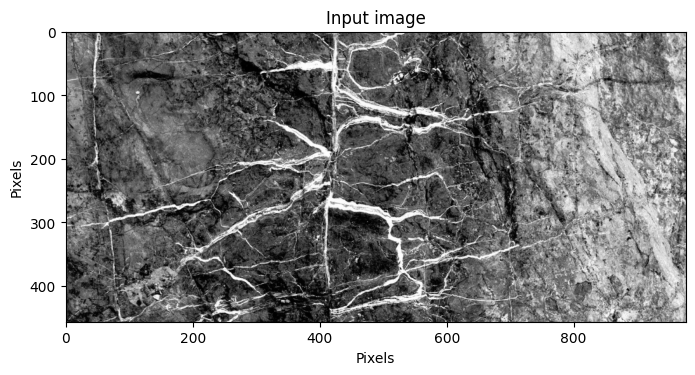

In [1]:
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt

DATA_DIR = "materials/CNN_crack_lab/CNN_lab/data"

image_input = sio.loadmat(f"{DATA_DIR}/image_input.mat")["image_input"].astype(np.float32)
train_mat = sio.loadmat(f"{DATA_DIR}/train_new.mat", struct_as_record=False, squeeze_me=True)["train"]
trainx = train_mat.trainx.astype(int)
trainz = train_mat.trainz.astype(int)
label = train_mat.label.astype(np.float32)  # (2, 400)

nz, nx = image_input.shape
print(f"Image size: {nz} x {nx}")
print(f"Training points: {trainx.shape[0]} ({int(label[0].sum())} crack, {int(label[1].sum())} non-crack)")

plt.figure(figsize=(8, 4))
plt.imshow(image_input, cmap="gray")
plt.title("Input image")
plt.xlabel("Pixels")
plt.ylabel("Pixels")
plt.show()

## 2. Discrepancies between the book text and the official code

As with Exercise 3, the book's prose, its own table, and the distributed code do not all agree. Documented here
rather than silently resolved, since the code is what actually runs:

1. **Table 10.2** lists "5 conv. layers" and a "4x4" patch size for the crack-detection CNN. **Code 10.5.1**
   (and the real `cnnsetup.m`/`test_example_CNN.m` downloaded for this exercise) define only **two** convolutional
   layers, with **5x5** kernels (6 output maps, then 12). Figure 2's own caption in `lab.html` agrees with the
   code: "two convolutional layer and a fully connected layer."
2. **Section 10.5.2** describes picking "400 crack and 400 non-crack" patches. **Code 10.5.1** and `lab.html`'s
   own procedure text both say 200 of each (`ntrain = 200`), which also matches the real `train_new.mat` used
   below (200 + 200).
3. The assignment text names **AlexNet**; the official code trains a small custom CNN from scratch, not AlexNet.
   This notebook follows the code.

## 3. Extracting the 400 labeled patches

Each training point is the center of a 17x17 patch (`wdx = wdz = 8` in Code 10.5.1, so `image_x = image_z =
2*8+1 = 17`). The image is first padded by replicating its border (`padimage.m`), then each 17x17 patch is
resized to 32x32 by bilinear interpolation (`interp2` with a grid spanning the patch corner to corner, i.e.
aligned corners), matching Code 10.5.1's upsampling step before the CNN.

Training patches: torch.Size([400, 1, 32, 32])


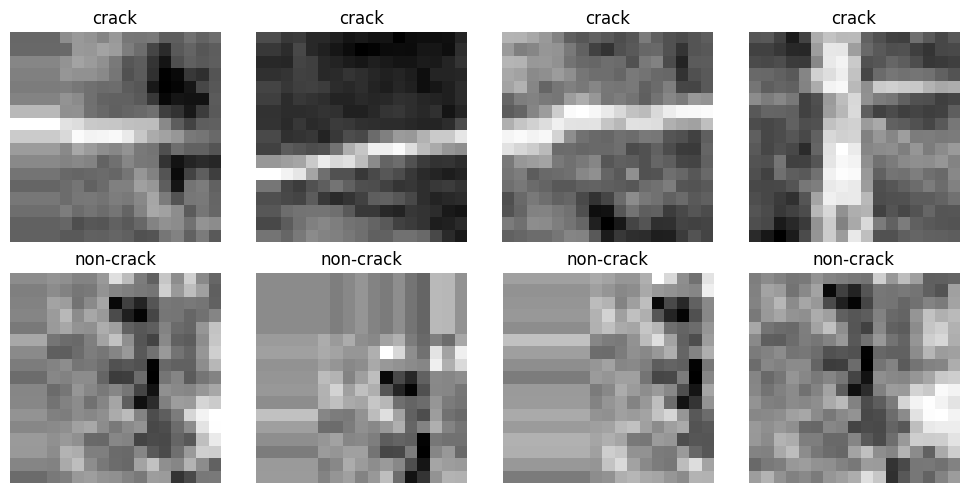

In [2]:
HALF = 8  # wdx = wdz = 8
PATCH = 2 * HALF + 1  # 17
RESIZED = 32

image_pad = np.pad(image_input, ((HALF, HALF), (HALF, HALF)), mode="edge")


def extract_patch(z1, x1):
    '''z1, x1 are 1-indexed MATLAB coordinates in the ORIGINAL image, matching
    image_pad(trainz:trainz+16, trainx:trainx+16) in test_example_CNN.m.'''
    z0, x0 = z1 - 1, x1 - 1
    return image_pad[z0:z0 + PATCH, x0:x0 + PATCH]


def resize_patches(patches):
    t = torch.tensor(patches, dtype=torch.float32).unsqueeze(1)
    return F.interpolate(t, size=(RESIZED, RESIZED), mode="bilinear", align_corners=True)


train_patches = np.stack([extract_patch(z, x) for z, x in zip(trainz, trainx)])
train_patches_resized = resize_patches(train_patches)
train_labels = torch.tensor(label.T, dtype=torch.float32)
print("Training patches:", train_patches_resized.shape)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
crack_idx = np.where(label[0] == 1)[0][:4]
noncrack_idx = np.where(label[1] == 1)[0][:4]
for col, idx in enumerate(crack_idx):
    axes[0, col].imshow(train_patches[idx], cmap="gray")
    axes[0, col].set_title("crack")
for col, idx in enumerate(noncrack_idx):
    axes[1, col].imshow(train_patches[idx], cmap="gray")
    axes[1, col].set_title("non-crack")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. CNN architecture and training

Matching `cnnsetup.m` / `cnnff.m` / `cnnbp.m` exactly: conv(1->6, 5x5) + sigmoid + average-pool(2), then
conv(6->12, 5x5) + sigmoid + average-pool(2), flattened into a fully connected layer to 2 outputs with a final
sigmoid (`net.o = sigm(...)` in `cnnff.m`). The loss is the quadratic misfit from `lab.html` Section 5
(`cnnbp.m`'s `net.L = 1/2 * sum(net.e.^2) / size(net.e,2)`), optimized with plain gradient descent
(`cnnapplygrads.m`). Hyperparameters are taken directly from `test_example_CNN.m`: `opts.alpha = 1` (learning
rate), `opts.batchsize = 20`, `opts.numepochs = 10`.

In [3]:
class CrackCNN(nn.Module):
    '''Two conv layers (6, 12 output maps; 5x5 kernels) with sigmoid + average pooling,
    then a fully connected sigmoid output layer, matching cnnsetup.m / cnnff.m.'''

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.conv2 = nn.Conv2d(6, 12, 5)
        self.fc = nn.Linear(12 * 5 * 5, 2)

    def forward(self, x):
        x = torch.sigmoid(self.conv1(x))
        x = F.avg_pool2d(x, 2)
        x = torch.sigmoid(self.conv2(x))
        x = F.avg_pool2d(x, 2)
        x = x.flatten(1)
        return torch.sigmoid(self.fc(x))


def train_cnn(model, patches, labels, alpha=1.0, batch_size=20, epochs=10, seed=0, verbose=True):
    opt = torch.optim.SGD(model.parameters(), lr=alpha)
    rng = np.random.default_rng(seed)
    n = patches.shape[0]
    for epoch in range(epochs):
        perm = rng.permutation(n)
        total_loss = 0.0
        for b in range(0, n, batch_size):
            idx = perm[b:b + batch_size]
            opt.zero_grad()
            pred = model(patches[idx])
            loss = F.mse_loss(pred, labels[idx])
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(idx)
        if verbose:
            print(f"epoch {epoch + 1}/{epochs}  loss={total_loss / n:.4f}")
    return model


torch.manual_seed(0)
model = CrackCNN()
train_cnn(model, train_patches_resized, train_labels)

with torch.no_grad():
    pred = model(train_patches_resized)
    train_acc = (pred.argmax(1) == train_labels.argmax(1)).float().mean().item()
print(f"Training accuracy after 10 epochs: {train_acc:.1%}")

epoch 1/10  loss=0.2734
epoch 2/10  loss=0.2525
epoch 3/10  loss=0.2536
epoch 4/10  loss=0.2524
epoch 5/10  loss=0.2471
epoch 6/10  loss=0.2365
epoch 7/10  loss=0.2120


epoch 8/10  loss=0.1813
epoch 9/10  loss=0.1556
epoch 10/10  loss=0.1364
Training accuracy after 10 epochs: 83.5%


## 5. Classifying every pixel of the image

`test_example_CNN.m` applies the trained CNN to a 17x17 patch centered at every pixel of the image (in chunks,
to limit memory). The same sliding-window extraction and resizing is used here, run in batches of 4096 patches.

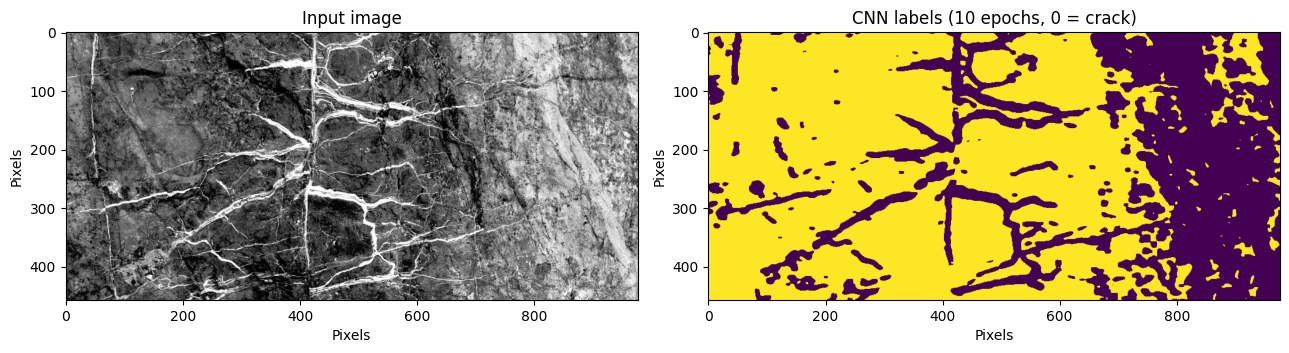

Fraction of the image classified as crack: 35.2%


In [4]:
def classify_full_image(model, chunk_size=4096):
    windows = sliding_window_view(image_pad, (PATCH, PATCH)).reshape(nz * nx, PATCH, PATCH)
    pred_map = np.zeros(nz * nx, dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for start in range(0, windows.shape[0], chunk_size):
            batch = resize_patches(windows[start:start + chunk_size])
            pred_map[start:start + chunk_size] = model(batch).argmax(1).numpy()
    return pred_map.reshape(nz, nx)


label_map = classify_full_image(model)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(image_input, cmap="gray")
axes[0].set_title("Input image")
axes[1].imshow(label_map, cmap="viridis")
axes[1].set_title("CNN labels (10 epochs, 0 = crack)")
for ax in axes:
    ax.set_xlabel("Pixels")
    ax.set_ylabel("Pixels")
plt.tight_layout()
plt.show()

print(f"Fraction of the image classified as crack: {(label_map == 0).mean():.1%}")

## 6. Why the right third of the image is misclassified

The classification map tracks the visible crack network reasonably well on the left two-thirds of the image,
but labels nearly the entire right portion as crack, even though that region shows a different, unbroken rock
texture. The cause is visible directly in the official training set, not in the CNN: the 200 non-crack points
in `train_new.mat` are not spread across the image. They are confined to a 9x17-pixel corner.

Crack points: x in (np.int64(6), np.int64(792))  z in (np.int64(1), np.int64(453))
Non-crack points: x in (np.int64(1), np.int64(9))  z in (np.int64(1), np.int64(17))  ( 9 distinct x values )


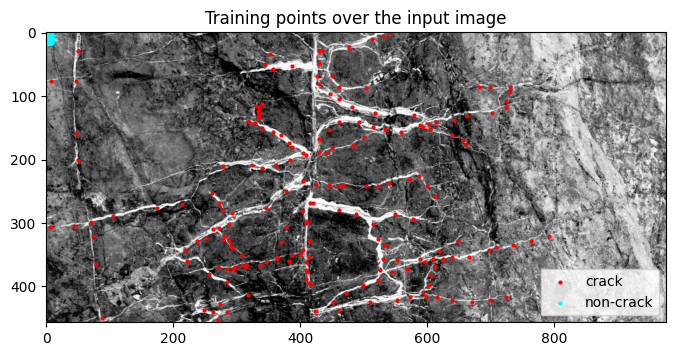

In [5]:
crack_mask = label[0] == 1
print("Crack points: x in", (trainx[crack_mask].min(), trainx[crack_mask].max()),
      " z in", (trainz[crack_mask].min(), trainz[crack_mask].max()))
print("Non-crack points: x in", (trainx[~crack_mask].min(), trainx[~crack_mask].max()),
      " z in", (trainz[~crack_mask].min(), trainz[~crack_mask].max()),
      " (", len(np.unique(trainx[~crack_mask])), "distinct x values )")

plt.figure(figsize=(8, 4))
plt.imshow(image_input, cmap="gray")
plt.scatter(trainx[crack_mask], trainz[crack_mask], s=4, c="red", label="crack")
plt.scatter(trainx[~crack_mask], trainz[~crack_mask], s=4, c="cyan", label="non-crack")
plt.legend(loc="lower right")
plt.title("Training points over the input image")
plt.show()

The non-crack class was sampled from a single small, uniform patch of background texture, repeated 200 times
with small jitter, instead of from a representative spread of non-crack regions. The CNN has never seen a
non-crack example resembling the brighter rock texture on the right, so it defaults to the other class there.
This is a property of the official training set, not an artifact of the Python port.

## 7. Section 6, Question 3: increasing the number of training iterations

`lab.html`'s own Section 6 asks: *"Increase the iteration number to 100. How the result will change? Why? Is
there anyway to prevent this problem."* `test_example_CNN.m` ships with `opts.numepochs = 10`; here the same
model is retrained from the same initialization for 60 epochs instead, well past the point where training
accuracy saturates, and the resulting classification map is compared to the 10-epoch one above.

Training accuracy after 60 epochs: 100.0%


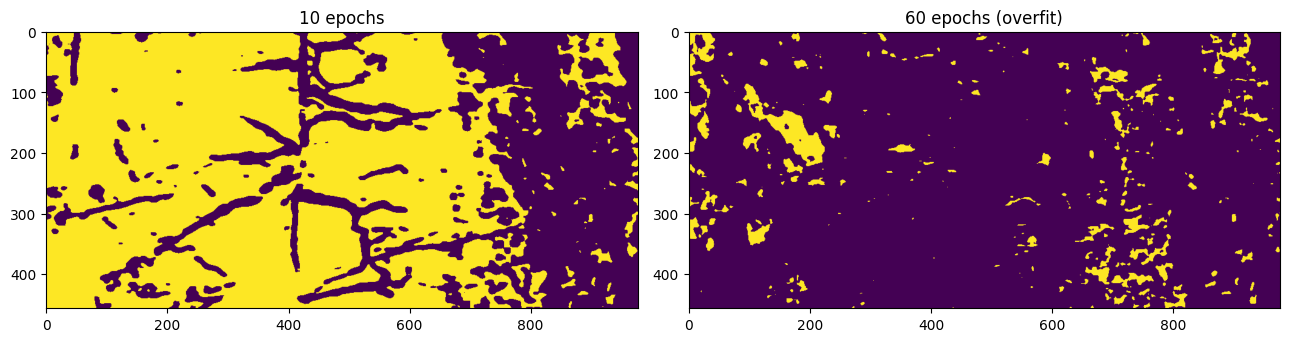

Crack fraction, 10 epochs: 35.2%
Crack fraction, 60 epochs: 93.4%


In [6]:
torch.manual_seed(0)
model_long = CrackCNN()
train_cnn(model_long, train_patches_resized, train_labels, epochs=60, verbose=False)

with torch.no_grad():
    pred_long = model_long(train_patches_resized)
    train_acc_long = (pred_long.argmax(1) == train_labels.argmax(1)).float().mean().item()
print(f"Training accuracy after 60 epochs: {train_acc_long:.1%}")

label_map_long = classify_full_image(model_long)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(label_map, cmap="viridis")
axes[0].set_title("10 epochs")
axes[1].imshow(label_map_long, cmap="viridis")
axes[1].set_title("60 epochs (overfit)")
plt.tight_layout()
plt.show()

print(f"Crack fraction, 10 epochs: {(label_map == 0).mean():.1%}")
print(f"Crack fraction, 60 epochs: {(label_map_long == 0).mean():.1%}")

## 8. Discussion

Training to 100% training accuracy (60 epochs) does not produce a better crack map; it produces a visibly worse
one. The 10-epoch model still traces the main crack network; the 60-epoch model instead fits fine details of
the 400 individual training patches and collapses into a speckled pattern unrelated to the visible cracks, with
the "crack" class now covering 93% of the image instead of 35%.

This happens because the training set is small (400 patches) and, per Section 6 above, severely skewed: the
non-crack class is a single uniform texture. More iterations let the network memorize that narrow training
distribution instead of learning a decision boundary that generalizes, which is the overfitting the lab's own
question anticipates. `opts.numepochs = 10` in the official code is a reasonable stopping point given this
training set, not an arbitrary choice.

The fix is not fewer iterations but a better training set: non-crack points should be sampled from a spread of
regions and textures across the image (not one corner), and a held-out validation split would let training stop
when validation accuracy, not training accuracy, stops improving.